# DINGO injection recovery: predict R and C directly

Use the **grism** kernel and run top to bottom. This notebook disperses a known rotating galaxy into R and C, then compares predicted images with the **original input pixels**.

First fit kinematics with the true emission map known, including **inclination with a Gaussian prior**. Then try a free emission map using a separate profile optimizer. The center stays fixed to truth in both tests. There is no PSF or intrinsic velocity dispersion yet.

The MCMC still knows the emission map: this tests freeing inclination alone, not the full unknown-map real-source posterior. Previous fixed-inclination outputs remain in `disk_200_forward`; this setup uses a new experiment directory.


In [1]:
from pathlib import Path
import os, sys, importlib, logging
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import display

REPO = Path.cwd() if (Path.cwd() / "dingo").is_dir() else Path("/home/aakavan/kinematics/grism-kinematics")
CALIBRATION_DIR = REPO.parent / "grism_cal"
SAVE_ROOT = REPO / "results" / "simulations"
EXPERIMENT = "disk_200_forward_i60s5"   # Change this name to keep another experiment
OVERRIDE = True                  # Regeneration replaces this named simulation and its fits
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Fitting prior in degrees; separate from the injected truth below.
INCLINATION_MEAN = 60.0           # None restores the original fixed-true-inclination test
INCLINATION_SIGMA = 5.0           # Gaussian 1-sigma width; inclination is bounded to 5..85 deg

sys.path.insert(0, str(REPO))
os.environ["GRISM_CAL_DIR"] = str(CALIBRATION_DIR)
torch.set_num_threads(min(4, os.cpu_count() or 1))
logging.getLogger("dingo.fitting").setLevel(logging.WARNING)
from dingo import simple_simulation as sim, simulation_review as inputs
from dingo import injection_forward as forward, injection_review as review, injection_flexible as flexible
for module in (sim, inputs, forward, review, flexible):
    importlib.reload(module)
print("Device:", DEVICE)
print("Saving to:", SAVE_ROOT / EXPERIMENT)

Device: cuda
Saving to: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200_forward_i60s5


## 1. Make the galaxy

These are the injected **true values**, not fitting guesses. Velocity means deprojected asymptotic $V_\infty$; radii/centers are pixels and angles are degrees. R and C get independent Gaussian noise. `noise_sigma=0` allows noiseless checks and skips MCMC.

Rerunning this cell with `OVERRIDE=True` replaces this named simulation, including its fits. To try a different start on the same images, rerun from step 3.

Inclination setting: {'mode': 'gaussian', 'mean_deg': 60.0, 'sigma_deg': 5.0, 'bounds_deg': [5.0, 85.0]}


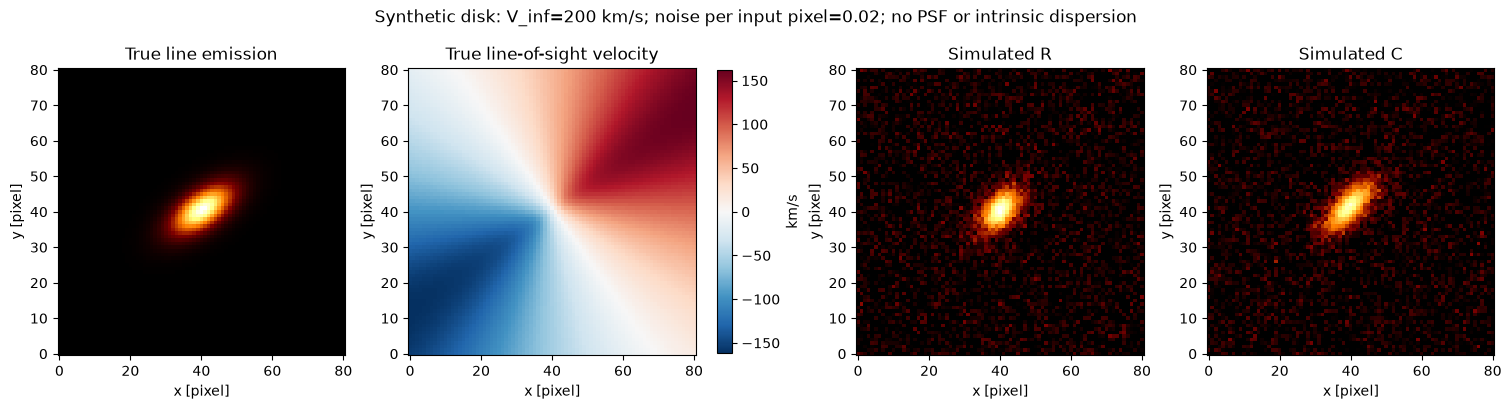

In [2]:
mock = sim.make_mock(
    SAVE_ROOT / EXPERIMENT,
    velocity=200.0, turnover=5.0, inclination=60.0, pa=35.0,
    center=(40.3, 40.7), effective_radius=6.0, peak=1.0,
    noise_sigma=0.02, seed=42, overwrite=OVERRIDE,
)
experiment = forward.ForwardExperiment(
    mock, device=DEVICE,
    inclination_mean=INCLINATION_MEAN, inclination_sigma=INCLINATION_SIGMA,
)
print("Inclination setting:", experiment.inclination_settings)
fig = inputs.show_inputs(mock)
display(fig)
plt.close(fig)

## 2. Check the direct prediction

The true emission map and all parameters except velocity are known here. The noiseless curve should reach zero residual at the injected velocity. Each plot subtracts its own minimum. This tests numerical consistency using the same forward model for generation and recovery; it does not yet establish real-data accuracy.

Direct R+C velocity check:   0%|          | 0/41 [00:00<?, ?it/s]

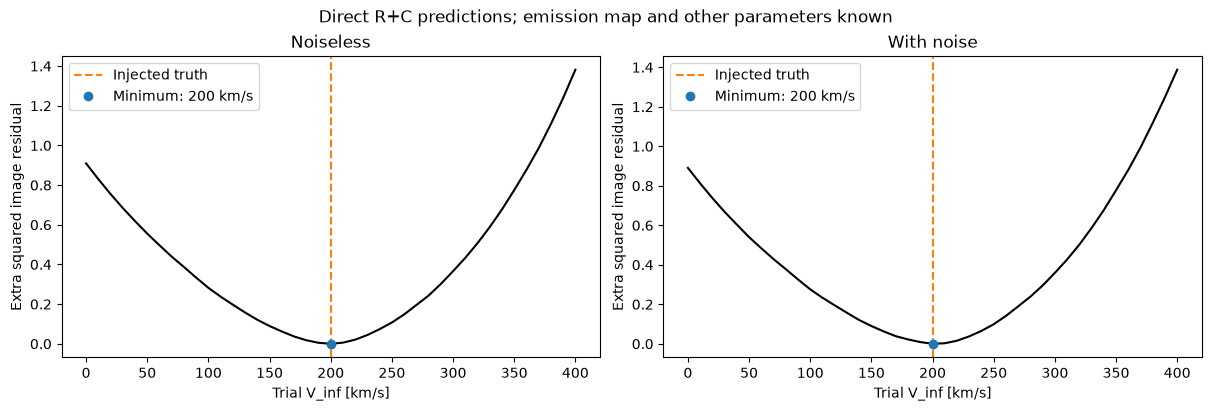

In [3]:
scan, fig = review.scan_velocity(experiment, np.arange(0.0, 401.0, 10.0))
display(fig)
plt.close(fig)

## 3. Fit from different starting velocities

Fit **velocity, turnover radius, orientation, R x/y registration, and inclination**. Inclination starts at the prior mean and is fitted with the configured Gaussian prior. The true emission map and center remain fixed. Setting `INCLINATION_MEAN=None` restores the original five-parameter fit with inclination fixed to truth.

The starts deliberately use a different turnover radius and orientation. The table includes the fitted inclination; `finished` refers only to the optimizer.


In [4]:
fits = {}
for start in (75.0, 350.0, 800.0):
    fits[start] = experiment.fit(
        start, start_turnover=3.0, start_pa=20.0, start_offset=(0.2, -0.2),
        noisy=experiment.sigma > 0, max_evaluations=2000,
    )
    print(f"Start {start:g}: fitted V_inf={fits[start]['theta'][0]:.2f} km/s; {fits[start]['message']}")
display(review.compare_starts(experiment, list(fits.values())))

Start 75: fitted V_inf=207.68 km/s; Optimization terminated successfully.
Start 350: fitted V_inf=197.80 km/s; Optimization terminated successfully.
Start 800: fitted V_inf=211.97 km/s; Maximum number of function evaluations has been exceeded.


,start_V_inf,fitted_V_inf,true_V_inf,fitted_R_t,fitted_PA_deg,R_dx,R_dy,chi2,finished,start_i_deg,fitted_i_deg,true_i_deg
0,75.0,207.678663,200.0,4.515608,33.418320,0.000352,0.002150,13066.283212,True,60.0,51.028299,60.0
1,350.0,197.803477,200.0,4.632299,34.250964,0.000726,0.001307,13066.280611,True,60.0,55.829090,60.0
2,800.0,211.967328,200.0,4.567897,33.913446,-0.001401,0.001391,13066.684490,False,60.0,49.515586,60.0


## 4. MCMC with the emission map known

Inclination is **sampled**, with the Gaussian prior set above (default **60 degrees +/- 5 degrees**, bounded to 5..85 degrees). Its uncertainty and correlation with velocity enter the posterior. Errors remain **conditional on the true emission map and center**; morphology uncertainty is not included.

Emcee uses the batched PyTorch prediction on the selected device. Progress bars and retained-sample checkpoints are enabled. These short defaults let you inspect recovery; longer chains and repeated noise realizations are needed to assess convergence and coverage.


In [5]:
MCMC_START = 350.0
RESULT_DIR = None
if experiment.sigma > 0:
    RESULT_DIR = review.sample(
        experiment, fits[MCMC_START],
        warmup=100, draws=500, walkers=32, seed=42,
        progress="notebook", overwrite=OVERRIDE,
    )
else:
    print("Noiseless test: inspect fitted values; no measurement-noise error bars.")

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Known-map conditional posterior saved in: /home/aakavan/kinematics/grism-kinematics/results/simulations/disk_200_forward_i60s5/direct_known_map


## 5. Compare MCMC with the truth

Orange lines mark the injected values, including inclination in degrees. Residual panels show **input - prediction** in each original grism image, divided by its known noise. Every retained walker enters the summaries. The table, corner plot, traces, and rotation curve save in `<experiment>/direct_known_map/`; `run_info.txt` records the inclination prior.

To reopen results, load `mock = sim.load_mock(SAVE_ROOT / EXPERIMENT)`, recreate `ForwardExperiment` with the **same inclination mean and width used for that run**, set `RESULT_DIR = mock.directory / "direct_known_map"`, and run this cell. To view the older fixed-inclination run, use its experiment name and `inclination_mean=None`.


Intervals condition on the true emission map, true center.
Inclination sampled: Gaussian 60 +/- 5 deg, bounded 5..85 deg.
Status: finished Acceptance: 0.49868749999999995
Retained steps / estimated autocorrelation time: [15.716326852212237, 17.149435676417873, 16.709278939765234, 16.70383364964702, 15.026224658108456, 17.5389863326449]


,truth,median,minus_16th,plus_84th
V_inf [km/s],200.0,207.221625,9.898875,11.775843
R_t [pixel],5.0,4.884904,0.324518,0.354527
PA [deg],35.0,34.065763,1.067535,1.046181
R_dx [pixel],0.0,-0.001586,0.010237,0.011159
R_dy [pixel],0.0,-0.001805,0.018234,0.020754
i [deg],60.0,56.040691,3.505604,2.990391


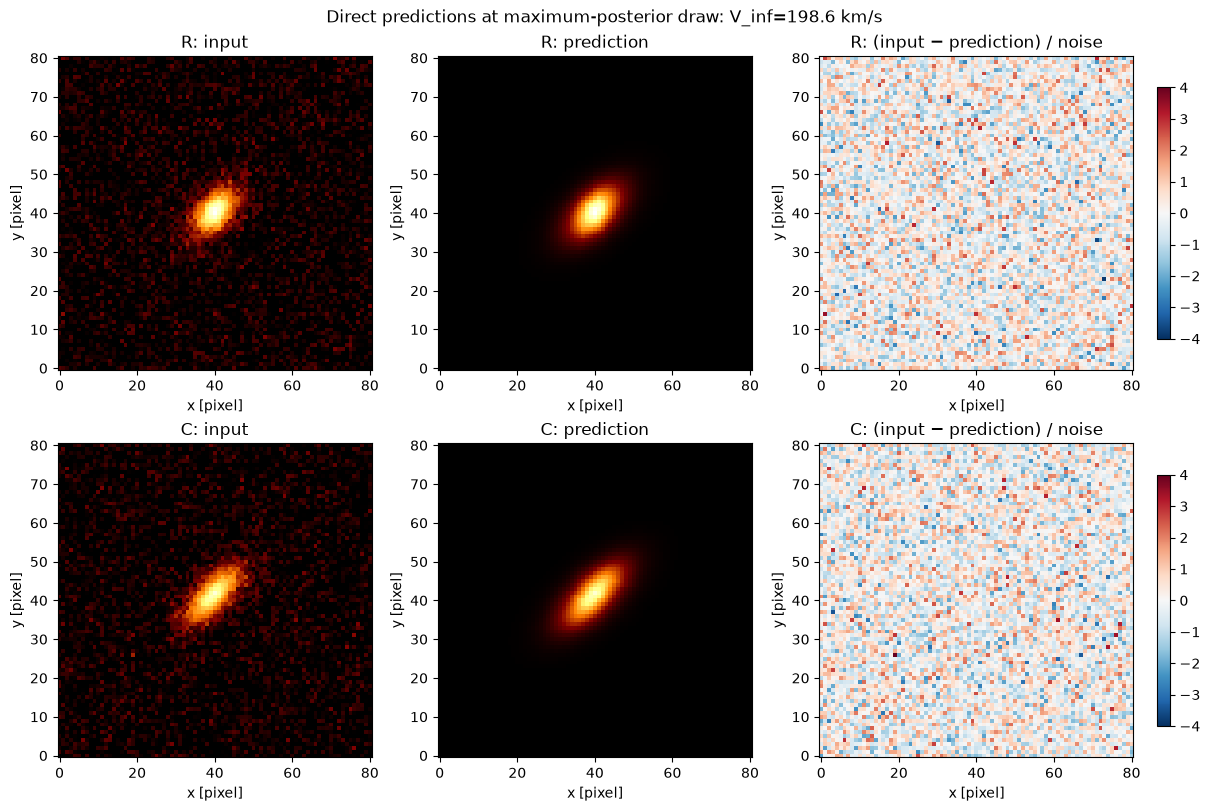

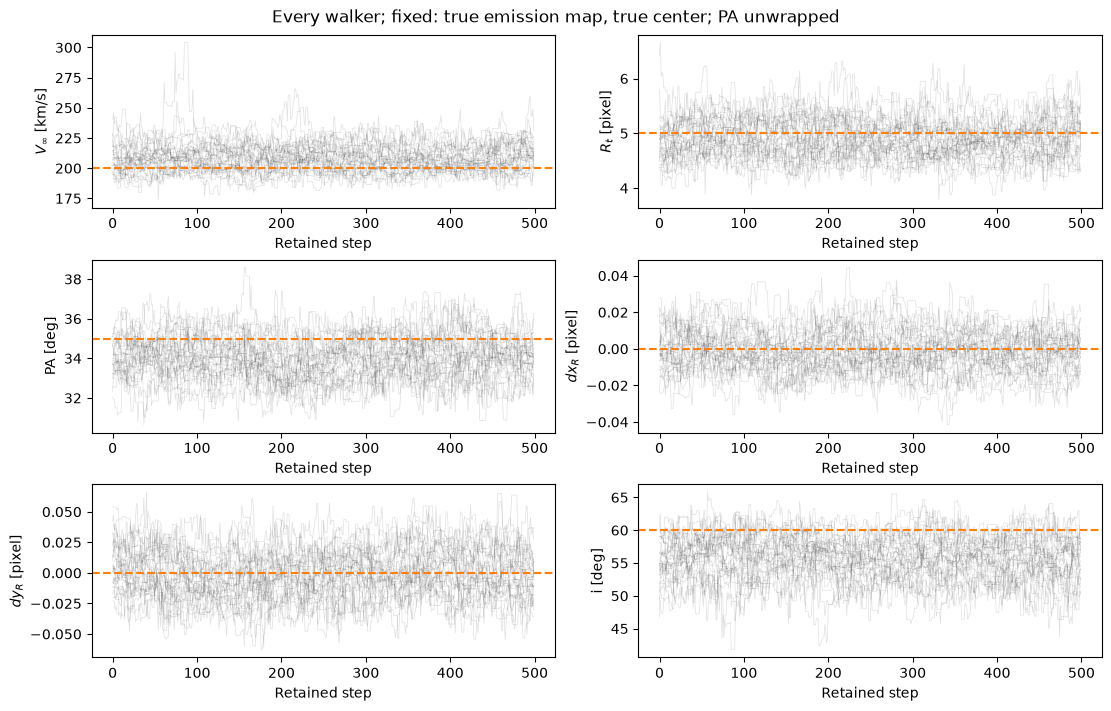

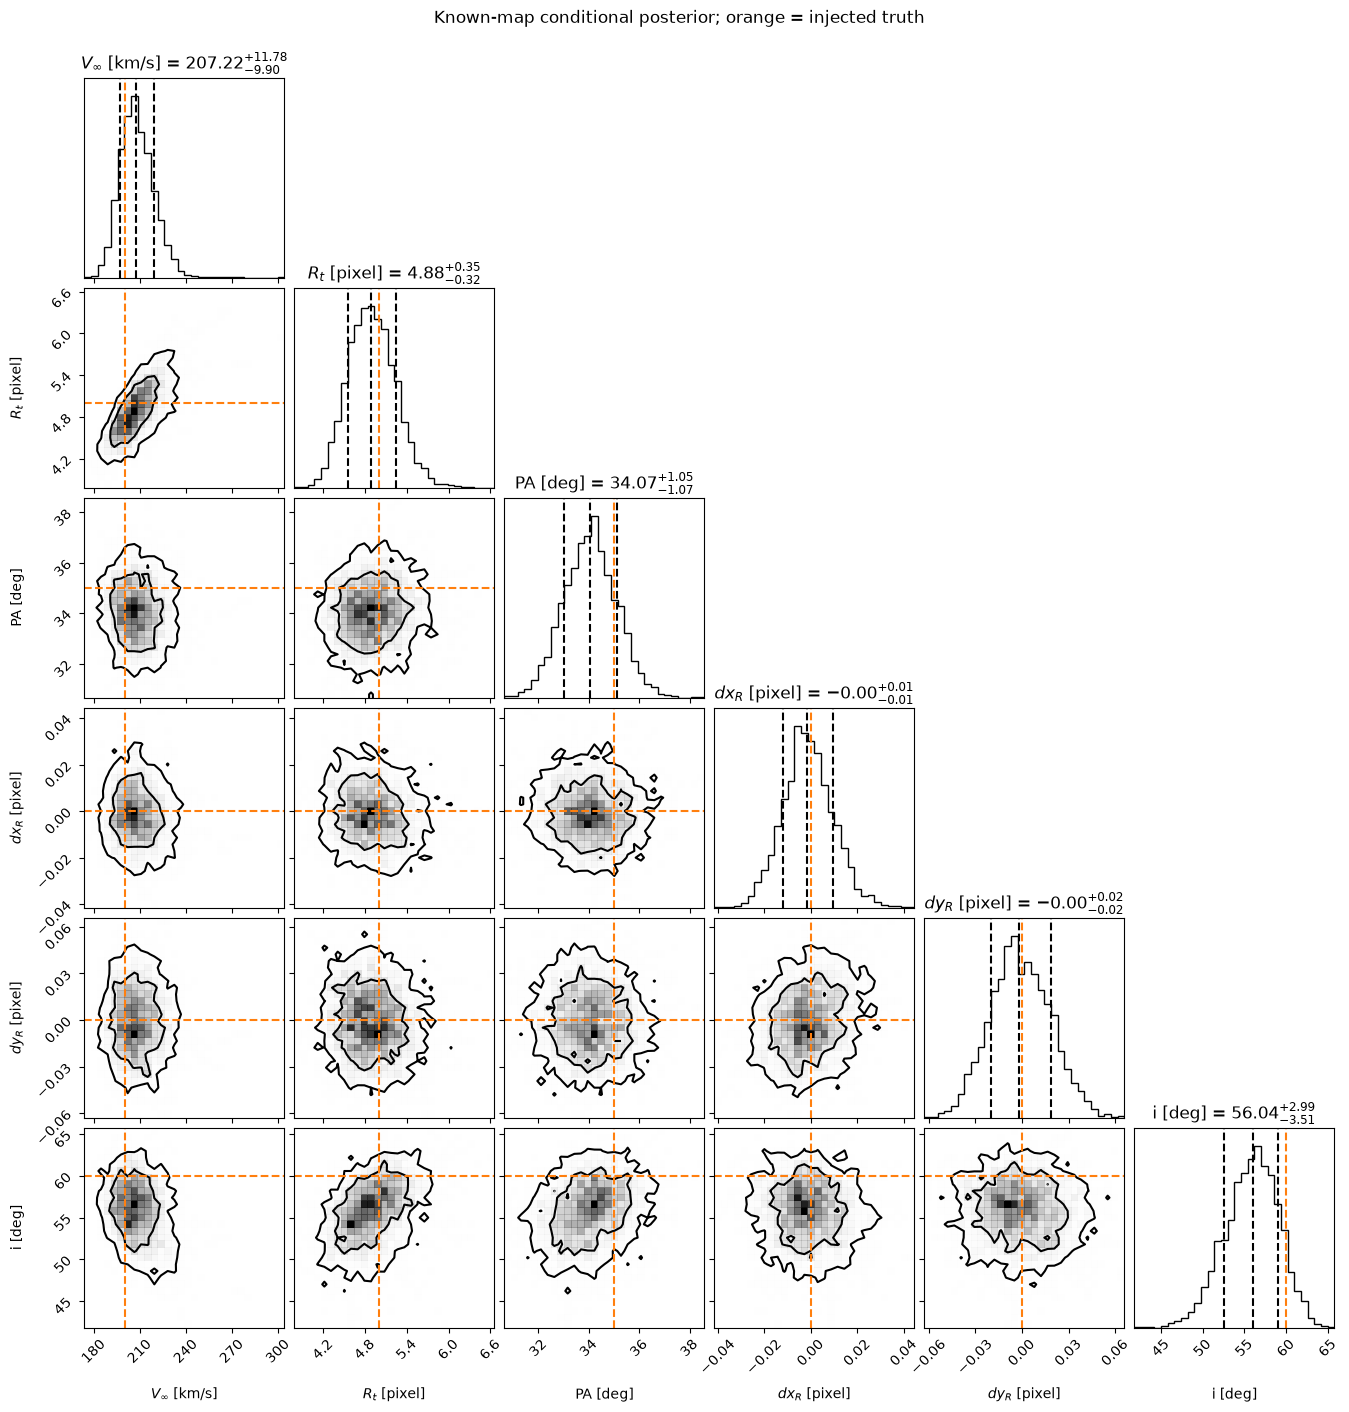

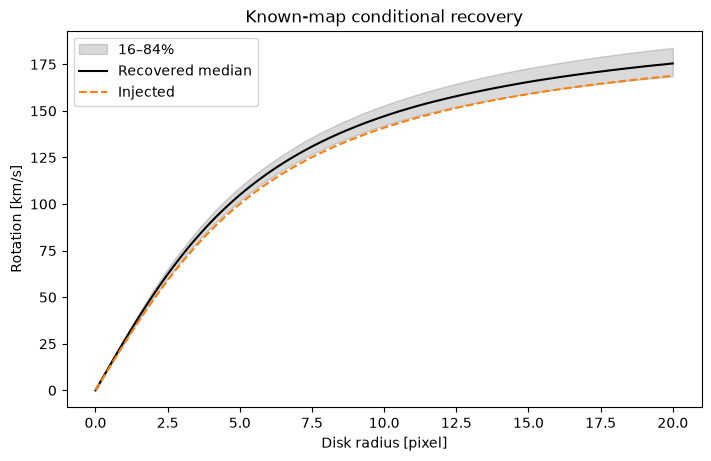

In [6]:
if RESULT_DIR is not None:
    views = review.show_results(experiment, RESULT_DIR)
    display(views["summary"])
    for name in ("residuals", "traces", "corner", "rotation_curve"):
        display(views[name])
        plt.close(views[name])

## 6. Let R+C determine the emission map (optional)

Now every source pixel has an independent **nonnegative** brightness fitted jointly to R and C. There is **no Sersic shape or smoothing prior**, and the injected emission map is not supplied to this solver.

The first scan deliberately holds **all other kinematic parameters, including inclination, at truth**. It is a conditional check, not a prior-marginalized velocity scan. The subsequent optimizer fits all six parameters with the configured inclination prior and the center fixed. With `INCLINATION_MEAN=None`, it fits the original five parameters instead.

This profiles over the map: it gives best fits, **not marginalized MCMC error bars**. The map solve uses CPU sparse linear algebra even when the coordinate model uses CUDA. Results save separately in `<experiment>/direct_free_map/`.


Free map: Noiseless:   0%|          | 0/17 [00:00<?, ?it/s]

Free map: With noise:   0%|          | 0/17 [00:00<?, ?it/s]

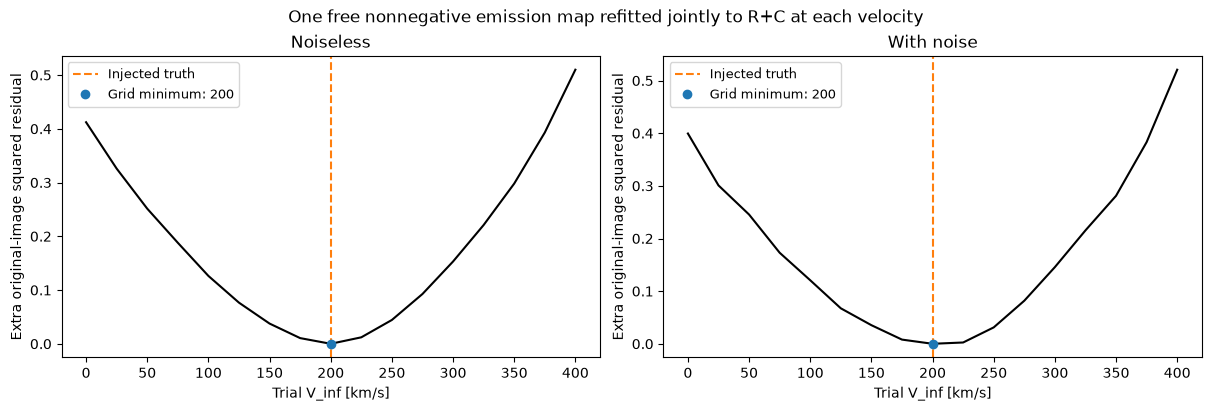

Free-map fit evaluations:   0%|          | 0/150 [00:00<?, ?it/s]

Free-map profile fit; no marginalized MCMC errors are reported.
Outer optimizer: True CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Inner nonnegative solve: True optimality: 7.044389260160966e-08
Outer gradient criterion met: False (a small change in the score can stop the optimizer before this criterion is met)


,truth,fitted
V_inf [km/s],200.0,285.996823
R_t [pixel],5.0,6.420214
PA [deg],35.0,9.542063
R_dx [pixel],0.0,0.104343
R_dy [pixel],0.0,0.735559
i [deg],60.0,56.687749


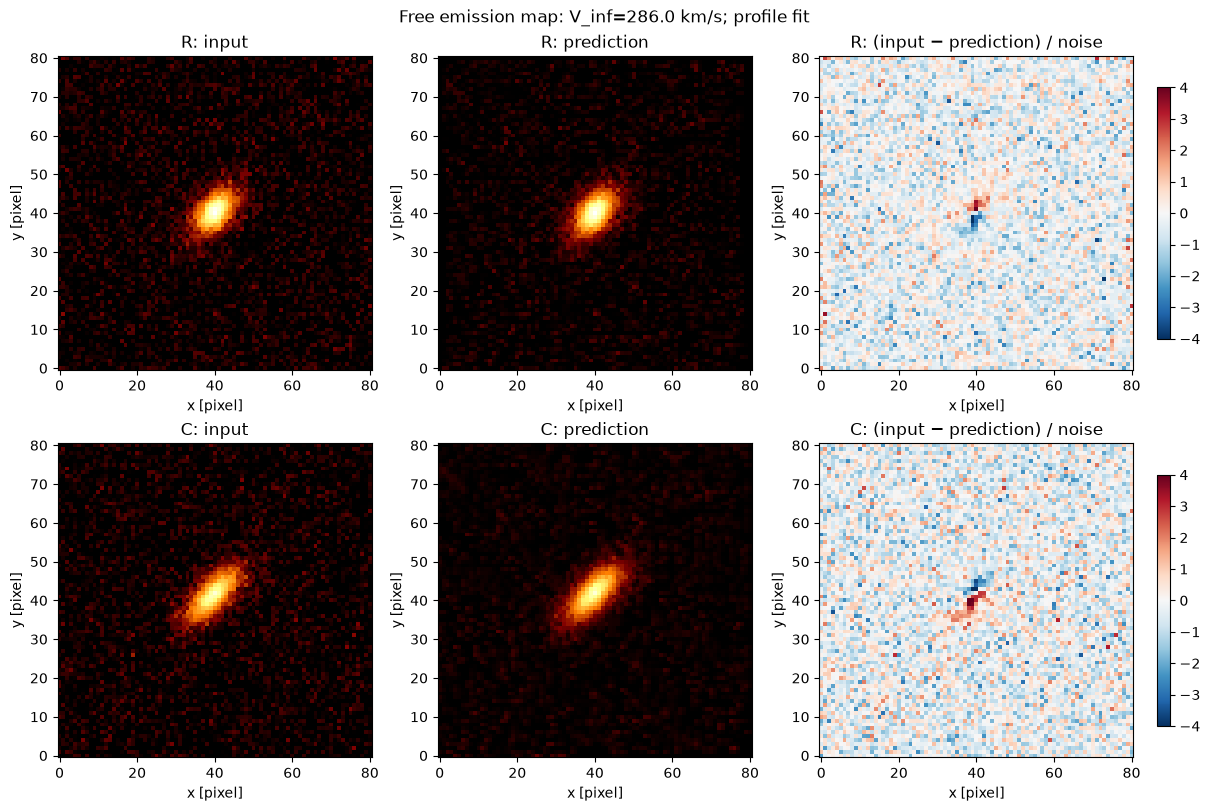

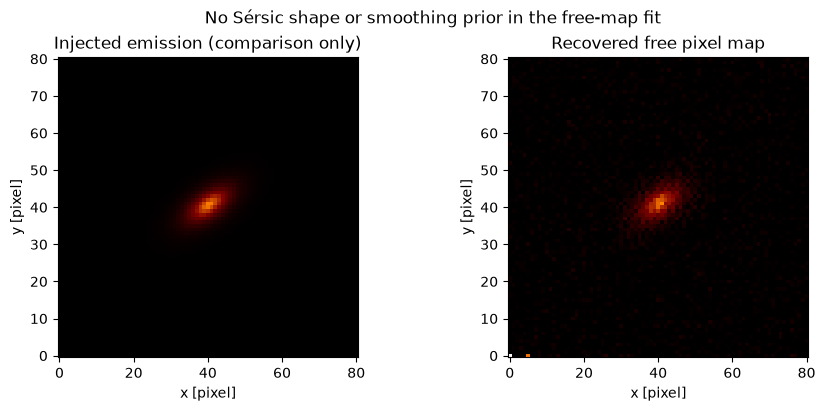

In [7]:
free_scan, fig = flexible.scan_velocity(experiment, np.arange(0.0, 401.0, 25.0))
display(fig)
plt.close(fig)

free_fit = flexible.fit(
    experiment, start_velocity=350.0, start_turnover=3.0, start_pa=20.0,
    start_offset=(0.2, -0.2), noisy=experiment.sigma > 0, max_evaluations=150,
)
free_views = review.show_free_result(experiment, free_fit)
display(free_views["summary"])
for name in ("residuals", "emission"):
    display(free_views[name])
    plt.close(free_views[name])